# Experiment 1 — Fresh-seed confirmation of centre phase gating

**Question.** Is the submitted hunt-only weak centre prior ($\lambda=.04$) preferable to applying the identical prior throughout non-emergency play, and does it have an observable effect relative to no centre prior?

**Confirmation scope.** This notebook formally re-evaluates `.04` phase gating with entirely fresh seeds. Notebooks 11 and 12 remain the development calibration and mechanism check; this experiment neither searches `.08/.12` nor reuses `65001–65040`.

## Locked design

| Variant | Locked definition |
|---|---|
| `center_off` | $\lambda=0$ |
| `center_hunt_04` | $\lambda=.04$, enabled only during the hunt phase |
| `center_ungated_04` | Retains the hunt-phase term and additionally applies the same $\lambda=.04$ outside the hunt phase in non-emergency states |

- Lineups: `external_mixed`, `frozen_dddqn`, `rule3`, `internal_mixed`.
- Fresh paired seeds: `69001–69040`; five rounds per lineup/variant/seed cell.
- Total: $4\times3\times40\times5=2{,}400$ rounds.
- Primary contrast: `center_hunt_04 − center_ungated_04`.
- Secondary contrast: `center_hunt_04 − center_off`.
- Primary outcome: mean score. Explanatory outcomes: coins, crates, kills, suicides, invalid actions, survival.
- Inference: average five rounds within seed, then a 10,000-replicate paired seed-cluster bootstrap.

## Mechanism definitions

`center_activation_rate` requires a nonzero lambda, an open phase gate, and at least one safe action with nonzero centre progress. `center_changed_action_rate` compares the actual action with a zero-centre counterfactual selected from the same Q values and identical RNG state. An economic intervention is such a change while coins or crates remain. Route overrides, actual invalid events, the network-only Q margin, and the adjusted pre-centre Q margin are logged for those interventions.

In [1]:
from __future__ import annotations
import hashlib, json
from collections import defaultdict
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RESULT_ROOT = ROOT / 'results' / 'e1_confirmatory_phase_gating'
payload = json.loads((RESULT_ROOT / 'summary.json').read_text())
protocol = payload['protocol']
assert protocol['total_rounds'] == 2400
assert len(payload['round_rows']) == 2400
assert len(payload['seed_rows']) == 480
assert len(payload['ledger']) == 480
{'rounds': len(payload['round_rows']), 'seed_rows': len(payload['seed_rows']),
 'ledger_entries': len(payload['ledger'])}

{'rounds': 2400, 'seed_rows': 480, 'ledger_entries': 480}

## Aggregate outcomes

Each row represents 40 seed clusters / 200 rounds. Rates are decision-weighted across all traces.

In [2]:
aggregate = pd.DataFrame(payload['aggregate'])
outcomes = ['lineup','variant','score','coins','crates','kills','suicides','invalid','survived']
display(aggregate[outcomes].round(3))

,lineup,variant,score,coins,crates,kills,suicides,invalid,survived
0,external_mixed,center_off,2.780,1.755,22.140,0.205,0.190,3.405,0.705
1,external_mixed,center_hunt_04,2.855,1.755,22.140,0.220,0.180,3.360,0.715
2,external_mixed,center_ungated_04,2.610,1.735,21.840,0.175,0.175,3.365,0.710
3,frozen_dddqn,center_off,3.415,2.190,27.675,0.245,0.270,3.365,0.670
4,frozen_dddqn,center_hunt_04,3.365,2.190,27.675,0.235,0.270,3.405,0.660
5,frozen_dddqn,center_ungated_04,3.310,2.210,28.590,0.220,0.245,3.225,0.655
6,rule3,center_off,4.075,3.200,30.860,0.175,0.140,1.645,0.800
7,rule3,center_hunt_04,4.125,3.200,30.860,0.185,0.140,1.640,0.800
8,rule3,center_ungated_04,4.055,3.180,31.040,0.175,0.150,1.595,0.795
9,internal_mixed,center_off,3.125,2.250,30.720,0.175,0.135,2.500,0.850


## Preregistered paired inference

Positive values are hunt-only minus comparator. For adverse outcomes such as suicides and invalid actions, negative values favour hunt-only.

In [3]:
bootstrap = pd.DataFrame(payload['paired_bootstrap'])
main_metrics = ['score','coins','crates','kills','suicides','invalid','survived']
display(bootstrap[bootstrap.metric.isin(main_metrics)][
    ['lineup','contrast','metric','mean_difference','ci_low','ci_high',
     'positive_seeds','zero_seeds','negative_seeds','paired_seeds']
].round(3))

,lineup,contrast,metric,mean_difference,ci_low,ci_high,positive_seeds,zero_seeds,negative_seeds,paired_seeds
0,external_mixed,center_hunt_04-center_ungated_04,score,0.245,-0.020,0.515,21,6,13,40
1,external_mixed,center_hunt_04-center_ungated_04,coins,0.020,-0.070,0.115,17,10,13,40
2,external_mixed,center_hunt_04-center_ungated_04,crates,0.300,-0.285,0.980,18,4,18,40
3,external_mixed,center_hunt_04-center_ungated_04,kills,0.045,-0.005,0.095,13,22,5,40
4,external_mixed,center_hunt_04-center_ungated_04,suicides,0.005,-0.040,0.055,9,21,10,40
5,external_mixed,center_hunt_04-center_ungated_04,invalid,-0.005,-0.355,0.350,19,4,17,40
6,external_mixed,center_hunt_04-center_ungated_04,survived,0.005,-0.045,0.050,11,21,8,40
18,external_mixed,center_hunt_04-center_off,score,0.075,0.000,0.175,3,37,0,40
19,external_mixed,center_hunt_04-center_off,coins,0.000,0.000,0.000,0,40,0,40
20,external_mixed,center_hunt_04-center_off,crates,0.000,0.000,0.000,0,40,0,40


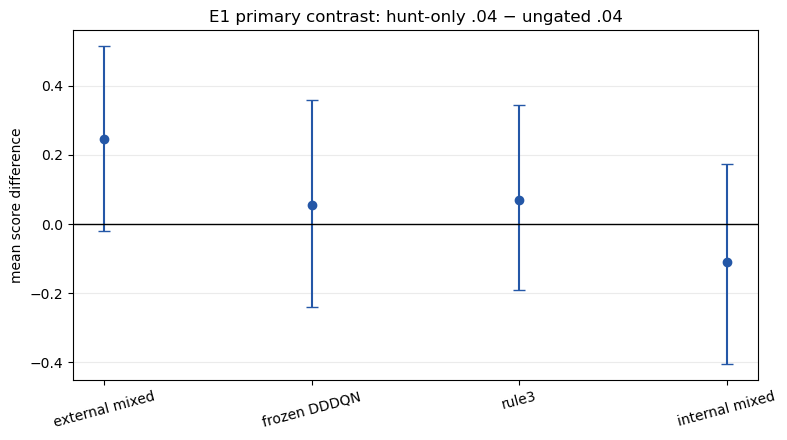

In [4]:
primary = bootstrap[(bootstrap.contrast == 'center_hunt_04-center_ungated_04') &
                    (bootstrap.metric == 'score')].set_index('lineup').loc[
    ['external_mixed','frozen_dddqn','rule3','internal_mixed']]
estimate = primary.mean_difference.to_numpy()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(np.arange(4), estimate,
            yerr=np.vstack([estimate-primary.ci_low.to_numpy(),
                            primary.ci_high.to_numpy()-estimate]),
            fmt='o', capsize=4, color='#2457A7')
ax.axhline(0, color='black', linewidth=1)
ax.set_xticks(np.arange(4), ['external mixed','frozen DDDQN','rule3','internal mixed'], rotation=15)
ax.set_ylabel('mean score difference')
ax.set_title('E1 primary contrast: hunt-only .04 − ungated .04')
ax.grid(axis='y', alpha=.25)
fig.tight_layout()
figure_dir = RESULT_ROOT / 'figures'; figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / 'primary_score_effects.png', dpi=180, bbox_inches='tight')
plt.show()

## Intervention mechanism

In [5]:
mechanism = [
    'lineup','variant','center_activation_rate','center_changed_action_rate',
    'economic_phase_center_interventions','economic_route_overrides',
    'economic_route_override_rate','intervention_invalid_actions',
    'intervention_invalid_rate','intervention_precenter_q_margin',
    'intervention_network_q_margin','hunt_center_distance','hunt_center_occupancy',
]
display(aggregate[mechanism].round(4))

,lineup,variant,center_activation_rate,center_changed_action_rate,economic_phase_center_interventions,economic_route_overrides,economic_route_override_rate,intervention_invalid_actions,intervention_invalid_rate,intervention_precenter_q_margin,intervention_network_q_margin,hunt_center_distance,hunt_center_occupancy
0,external_mixed,center_off,0.0000,0.0000,0.000,0.000,0.0000,0.0,0.0,NaN,NaN,0.2615,0.8467
1,external_mixed,center_hunt_04,0.1235,0.0013,0.000,0.000,0.0000,0.0,0.0,NaN,NaN,0.2470,0.8540
2,external_mixed,center_ungated_04,0.2817,0.0036,0.790,0.050,0.0633,0.0,0.0,-0.0215,-0.0429,0.2319,0.8603
3,frozen_dddqn,center_off,0.0000,0.0000,0.000,0.000,0.0000,0.0,0.0,NaN,NaN,0.3685,0.7828
4,frozen_dddqn,center_hunt_04,0.1559,0.0019,0.000,0.000,0.0000,0.0,0.0,NaN,NaN,0.3238,0.8050
5,frozen_dddqn,center_ungated_04,0.3031,0.0043,0.865,0.035,0.0405,0.0,0.0,-0.0201,-0.2101,0.3147,0.8105
6,rule3,center_off,0.0000,0.0000,0.000,0.000,0.0000,0.0,0.0,NaN,NaN,0.2001,0.8779
7,rule3,center_hunt_04,0.0782,0.0006,0.000,0.000,0.0000,0.0,0.0,NaN,NaN,0.1823,0.8883
8,rule3,center_ungated_04,0.2458,0.0032,0.805,0.050,0.0621,0.0,0.0,-0.0210,-0.0390,0.1765,0.8910
9,internal_mixed,center_off,0.0000,0.0000,0.000,0.000,0.0000,0.0,0.0,NaN,NaN,0.2895,0.8260


## Confirmatory result

For the primary hunt-only minus ungated contrast, mean-score effects were `external_mixed` +0.245 (95% CI -0.020 to +0.515); `frozen_dddqn` +0.055 (95% CI -0.240 to +0.360); `rule3` +0.070 (95% CI -0.190 to +0.345); `internal_mixed` -0.110 (95% CI -0.405 to +0.175).

For the secondary hunt-only minus centre-off contrast, effects were `external_mixed` +0.075 (95% CI +0.000 to +0.175); `frozen_dddqn` -0.050 (95% CI -0.200 to +0.100); `rule3` +0.050 (95% CI +0.000 to +0.150); `internal_mixed` +0.125 (95% CI -0.050 to +0.350).

The preregistered evidence does not establish a universal score advantage for hunt-only gating. The centre prior is therefore interpreted as a conservative priority rule, not a generally performance-improving optimisation. The mechanism tables below distinguish a prior that rarely changes actions from one that intervenes in economic routing with pool-dependent gains and costs. Coins, crates, kills, suicides, invalid actions, and survival remain prespecified explanatory outcomes rather than additional primary endpoints.

The clearest explanatory difference in the primary contrast is in `frozen_dddqn`: hunt-only collected 0.915 fewer crates/round than ungated (-1.700 to -0.170). Other primary score and safety intervals include zero. Ungated changed only 0.32%–0.43% of all decisions, corresponding to 0.765–0.865 economic-phase interventions per round. Only 0.015–0.050 per round actually overrode the active coin/crate route, and 0 logged intervention decisions directly produced an invalid action.

Relative to centre-off, hunt-only reduces hunt centre distance clearly in `frozen_dddqn` and `rule3`, with corresponding clear occupancy increases, but the changes are small and do not yield a stable cross-pool score effect. Overall, the data fit the narrow interpretation that $.04$ controllably modifies some hunt positioning while its score and economy effects remain small or opponent-pool dependent.

## Integrity audit

Every manifest is bound to the locked protocol and raw/trace hashes. The audit below additionally verifies that all three variants share identical five-round initial-condition hashes within every lineup/seed block.

In [6]:
protocol_hash = hashlib.sha256((RESULT_ROOT / 'protocol.json').read_bytes()).hexdigest()
initial = defaultdict(dict)
protocol_hashes = set()
for item in payload['ledger']:
    manifest = json.loads((ROOT / item['manifest']).read_text())
    assert manifest['raw_sha256'] == hashlib.sha256((ROOT / manifest['raw_stats']).read_bytes()).hexdigest()
    assert manifest['trace_sha256'] == hashlib.sha256((ROOT / manifest['trace']).read_bytes()).hexdigest()
    initial[(item['lineup'], item['seed'])][item['variant']] = tuple(
        entry['sha256'] for entry in manifest['initial_conditions'])
    protocol_hashes.add(manifest['protocol_sha256'])
audit = {
    'paired_lineup_seed_blocks': len(initial),
    'all_three_variants_present': all(len(group) == 3 for group in initial.values()),
    'all_initial_conditions_match': all(len(set(group.values())) == 1 for group in initial.values()),
    'one_locked_protocol': protocol_hashes == {protocol_hash},
    'protocol_sha256': protocol_hash,
    'implementation_sha256': protocol['implementation_sha256'],
}
assert all(value for key, value in audit.items() if key not in {'protocol_sha256','implementation_sha256'})
audit

{'paired_lineup_seed_blocks': 160,
 'all_three_variants_present': True,
 'all_initial_conditions_match': True,
 'one_locked_protocol': True,
 'protocol_sha256': '6fd30ee47e9b40f8c80a4f350e4621abdd72e3b25cea4f187c6790102ad60f58',
 'implementation_sha256': 'c7664198822d5dbcc96abdf6472799e7806bdaa990601c90b5facf21da8b8b33'}

## Reproduction entry points

The locked runner is `evaluation/e1_confirmatory_phase_gating.py`. The immutable protocol, per-cluster manifests, raw statistics, decision traces, seed rows, aggregate rows, and paired-bootstrap estimates are stored under `results/e1_confirmatory_phase_gating/`. Notebook 11 and notebook 12 remain historical development evidence and are not pooled into this confirmatory analysis.
        